In [4]:
from datasets import load_dataset
from transformers import BertTokenizer
import random

# Load the dataset
dataset = load_dataset("Helsinki-NLP/opus_books", "en-es", split="train")

# Load the BERT multilingual cased tokenizer
tokenizer = BertTokenizer.from_pretrained("bert-base-multilingual-cased")

# Shuffle dataset to get diverse samples
dataset = dataset.shuffle(seed=42)

filtered_pairs = []

# Iterate and filter based on English token length
for example in dataset:
    en_text = example["translation"]["en"]
    es_text = example["translation"]["es"]

    en_tokens = tokenizer.tokenize(en_text)
    token_len = len(en_tokens)

    if 40 < token_len < 50:
        filtered_pairs.append({
            "en_text": en_text,
            "es_text": es_text,
            "en_tokens": en_tokens,
            "es_tokens": tokenizer.tokenize(es_text)
        })

    if len(filtered_pairs) == 1000:
        break

# Display some examples
for i in range(3):
    print(f"\nExample {i+1}")
    print("English:", filtered_pairs[i]["en_text"])
    print("Spanish:", filtered_pairs[i]["es_text"])
    print("English Tokens:", filtered_pairs[i]["en_tokens"])
    print("Spanish Tokens:", filtered_pairs[i]["es_tokens"])

# Save to file (optional)
import json
with open("tokenized_translation_pairs.json", "w", encoding="utf-8") as f:
    json.dump(filtered_pairs, f, ensure_ascii=False, indent=2)



Example 1
English: "I think as master does," Conseil replied, "and it's extremely possible that after crossing every sea on the globe, Captain Nemo will bid the three of us a fond farewell."
Spanish: -Yo pienso como el señor -dijo Conseil-, y es muy posible que tras haber recorrido todos los mares del Globo, el capitán Nemo nos dé el vuelo a los tres.
English Tokens: ['"', 'I', 'think', 'as', 'master', 'does', ',', '"', 'Conseil', 'rep', '##lied', ',', '"', 'and', 'it', "'", 's', 'extremely', 'possible', 'that', 'after', 'crossing', 'every', 'sea', 'on', 'the', 'globe', ',', 'Captain', 'Nem', '##o', 'will', 'bid', 'the', 'three', 'of', 'us', 'a', 'fond', 'fare', '##well', '.', '"']
Spanish Tokens: ['-', 'Yo', 'pie', '##ns', '##o', 'como', 'el', 'señor', '-', 'dijo', 'Conseil', '-', ',', 'y', 'es', 'muy', 'posible', 'que', 'tras', 'haber', 'recorrido', 'todos', 'los', 'mare', '##s', 'del', 'Globo', ',', 'el', 'capitán', 'Nem', '##o', 'nos', 'dé', 'el', 'vuelo', 'a', 'los', 'tres', '.']

Tokenizing: 100%|██████████| 5000/5000 [00:03<00:00, 1328.63it/s]


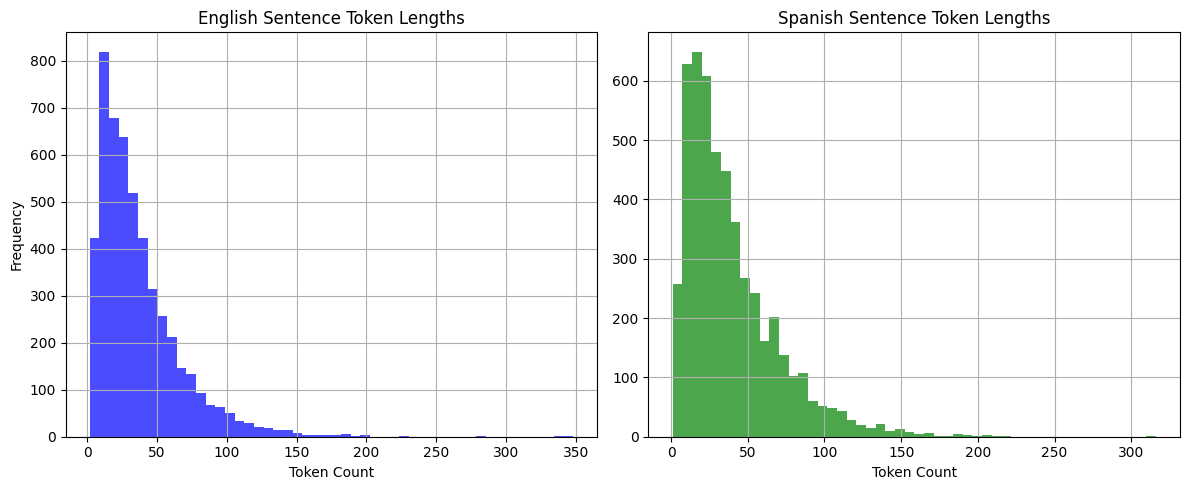


🔢 Average English/Spanish token length ratio: 0.958


In [7]:
import os
import matplotlib.pyplot as plt
from datasets import load_dataset
from transformers import AutoTokenizer
from tqdm import tqdm
import numpy as np

# Set Hugging Face token (replace with your actual token)
HF_TOKEN = "hf_...jACc"
os.environ["HUGGINGFACE_HUB_TOKEN"] = HF_TOKEN

# Load the BERT multilingual cased tokenizer
tokenizer = BertTokenizer.from_pretrained("bert-base-multilingual-cased")


# Load dataset
dataset = load_dataset("Helsinki-NLP/opus_books", "en-es", split="train")

# Filter valid examples
dataset = dataset.filter(lambda x: x["translation"].get("en") and x["translation"].get("es"))

# Limit for speed (adjust if needed)
MAX_SAMPLES = 5000
dataset = dataset.select(range(min(MAX_SAMPLES, len(dataset))))

# Token length storage
en_lengths = []
es_lengths = []

# Process with tqdm for progress
for sample in tqdm(dataset, desc="Tokenizing"):
    en_text = sample["translation"]["en"]
    es_text = sample["translation"]["es"]
    
    en_tokens = tokenizer.tokenize(en_text)
    es_tokens = tokenizer.tokenize(es_text)

    en_lengths.append(len(en_tokens))
    es_lengths.append(len(es_tokens))

# Plot histograms
plt.figure(figsize=(12, 5))

plt.subplot(1, 2, 1)
plt.hist(en_lengths, bins=50, color='blue', alpha=0.7, label='English')
plt.title("English Sentence Token Lengths")
plt.xlabel("Token Count")
plt.ylabel("Frequency")
plt.grid(True)

plt.subplot(1, 2, 2)
plt.hist(es_lengths, bins=50, color='green', alpha=0.7, label='Spanish')
plt.title("Spanish Sentence Token Lengths")
plt.xlabel("Token Count")
plt.grid(True)

plt.tight_layout()
plt.show()

# Compute average ratio
ratios = [en / es if es > 0 else 0 for en, es in zip(en_lengths, es_lengths)]
avg_ratio = np.mean(ratios)

print(f"\n🔢 Average English/Spanish token length ratio: {avg_ratio:.3f}")


Tokenizing and Filtering: 100%|██████████| 15000/15000 [00:03<00:00, 4338.90it/s]


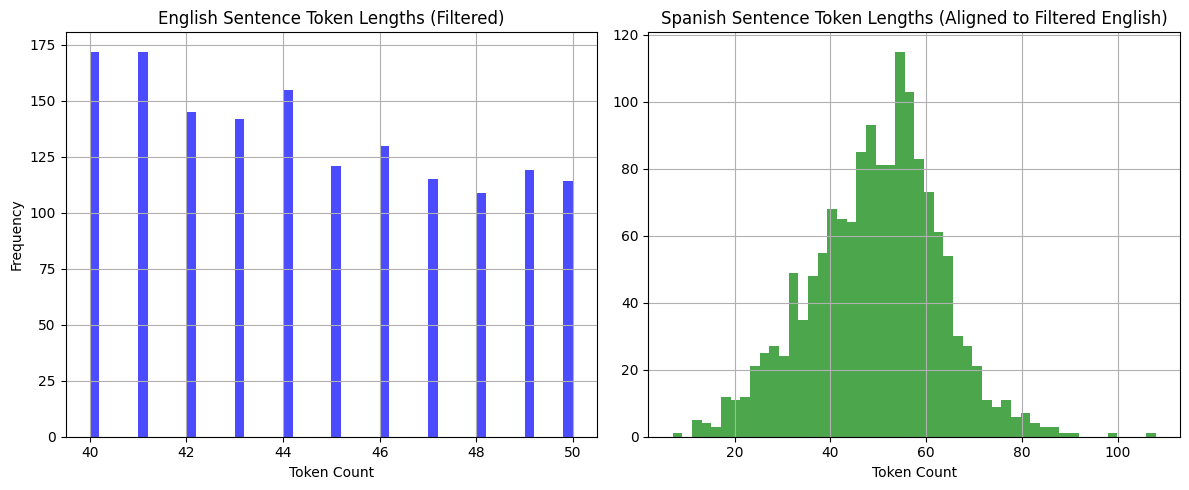


🔢 Average English/Spanish token length ratio (for 40–50 token English sentences): 0.989


In [31]:
import os
import matplotlib.pyplot as plt
from datasets import load_dataset
from transformers import BertTokenizer
from tqdm import tqdm
import numpy as np

deep_seek_tokenizer_path = "/home/laios/translations/LLM/deepseek_tokenizer"
tokenizer = AutoTokenizer.from_pretrained(deep_seek_tokenizer_path,
                                          # padding_side='left',
                                          device_map="auto",)

# Load dataset
dataset = load_dataset("Helsinki-NLP/opus_books", "en-es", split="train")

# Filter valid examples
dataset = dataset.filter(lambda x: x["translation"].get("en") and x["translation"].get("es"))

# Limit for speed (adjust if needed)
MAX_SAMPLES = 15000
dataset = dataset.select(range(min(MAX_SAMPLES, len(dataset))))

# Token length storage
en_lengths = []
es_lengths = []

# Filtered text storage (optional, for further processing)
filtered_en_texts = []
filtered_es_texts = []

# Tokenize and filter by English token length
for sample in tqdm(dataset, desc="Tokenizing and Filtering"):
    en_text = sample["translation"]["en"]
    es_text = sample["translation"]["es"]

    en_tokens = tokenizer.tokenize(en_text)
    if 40 <= len(en_tokens) <= 50:
        es_tokens = tokenizer.tokenize(es_text)

        en_lengths.append(len(en_tokens))
        es_lengths.append(len(es_tokens))

        filtered_en_texts.append(en_text)
        filtered_es_texts.append(es_text)

# Plot histograms
plt.figure(figsize=(12, 5))

plt.subplot(1, 2, 1)
plt.hist(en_lengths, bins=50, color='blue', alpha=0.7)
plt.title("English Sentence Token Lengths (Filtered)")
plt.xlabel("Token Count")
plt.ylabel("Frequency")
plt.grid(True)

plt.subplot(1, 2, 2)
plt.hist(es_lengths, bins=50, color='green', alpha=0.7)
plt.title("Spanish Sentence Token Lengths (Aligned to Filtered English)")
plt.xlabel("Token Count")
plt.grid(True)

plt.tight_layout()
plt.show()

# Compute average English/Spanish token length ratio
ratios = [en / es if es > 0 else 0 for en, es in zip(en_lengths, es_lengths)]
avg_ratio = np.mean(ratios)

print(f"\n🔢 Average English/Spanish token length ratio (for 40–50 token English sentences): {avg_ratio:.3f}")


In [24]:
# Count exact matches in token length
exact_match_count = sum(en == es for en, es in zip(en_lengths, es_lengths))
total_pairs = len(en_lengths)
percent_match = (exact_match_count / total_pairs) * 100 if total_pairs > 0 else 0

print(f"✅ Number of exact token length matches: {exact_match_count} out of {total_pairs}")
print(f"📊 Percentage of matches: {percent_match:.2f}%")


✅ Number of exact token length matches: 61 out of 1635
📊 Percentage of matches: 3.73%


# Italian

Tokenizing and Filtering: 100%|██████████| 15000/15000 [00:03<00:00, 4027.49it/s]


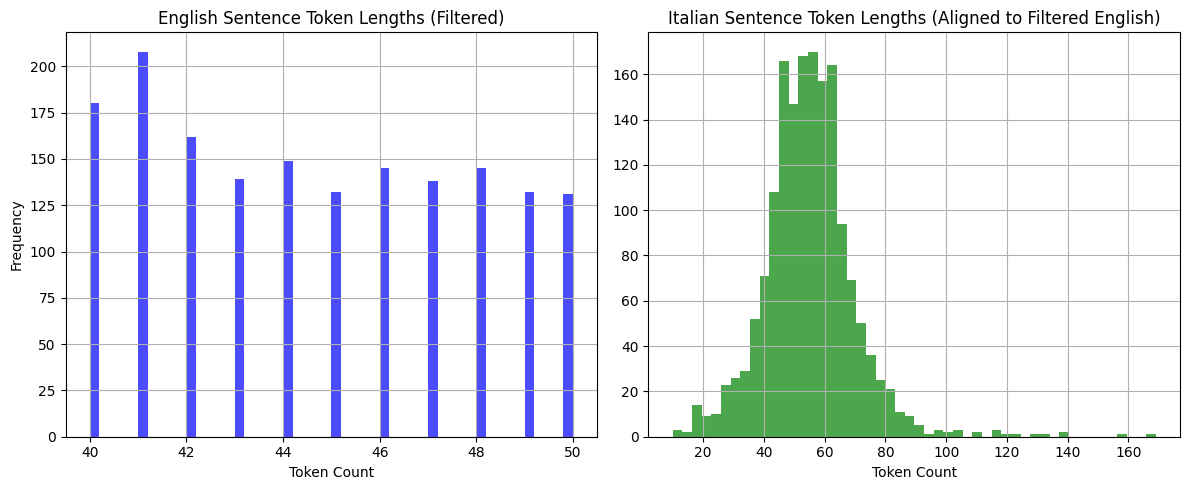


🔢 Average English/Italian token length ratio (for 40–50 token English sentences): 0.880


In [30]:
import os
import matplotlib.pyplot as plt
from datasets import load_dataset
from transformers import BertTokenizer
from tqdm import tqdm
import numpy as np

deep_seek_tokenizer_path = "/home/laios/translations/LLM/deepseek_tokenizer"
tokenizer = AutoTokenizer.from_pretrained(deep_seek_tokenizer_path,
                                          # padding_side='left',
                                          device_map="auto",)

# Load dataset
dataset = load_dataset("Helsinki-NLP/opus_books", "en-it", split="train")

# Filter valid examples
dataset = dataset.filter(lambda x: x["translation"].get("en") and x["translation"].get("it"))

# Limit for speed (adjust if needed)
MAX_SAMPLES = 15000
dataset = dataset.select(range(min(MAX_SAMPLES, len(dataset))))

# Token length storage
en_lengths = []
es_lengths = []

# Filtered text storage (optional, for further processing)
filtered_en_texts = []
filtered_es_texts = []

# Tokenize and filter by English token length
for sample in tqdm(dataset, desc="Tokenizing and Filtering"):
    en_text = sample["translation"]["en"]
    es_text = sample["translation"]["it"]

    en_tokens = tokenizer.tokenize(en_text)
    if 40 <= len(en_tokens) <= 50:
        es_tokens = tokenizer.tokenize(es_text)

        en_lengths.append(len(en_tokens))
        es_lengths.append(len(es_tokens))

        filtered_en_texts.append(en_text)
        filtered_es_texts.append(es_text)

# Plot histograms
plt.figure(figsize=(12, 5))

plt.subplot(1, 2, 1)
plt.hist(en_lengths, bins=50, color='blue', alpha=0.7)
plt.title("English Sentence Token Lengths (Filtered)")
plt.xlabel("Token Count")
plt.ylabel("Frequency")
plt.grid(True)

plt.subplot(1, 2, 2)
plt.hist(es_lengths, bins=50, color='green', alpha=0.7)
plt.title("Italian Sentence Token Lengths (Aligned to Filtered English)")
plt.xlabel("Token Count")
plt.grid(True)

plt.tight_layout()
plt.show()

# Compute average English/Italian token length ratio
ratios = [en / es if es > 0 else 0 for en, es in zip(en_lengths, es_lengths)]
avg_ratio = np.mean(ratios)

print(f"\n🔢 Average English/Italian token length ratio (for 40–50 token English sentences): {avg_ratio:.3f}")


# Spanish Italian

Tokenizing and Filtering: 100%|██████████| 15000/15000 [00:03<00:00, 4584.82it/s]


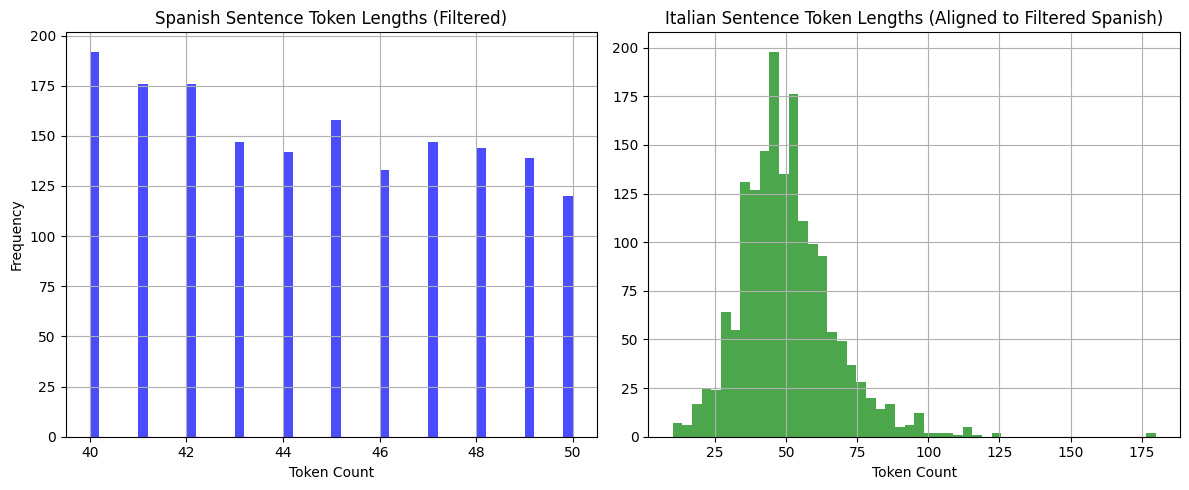


🔢 Average Spanish/Italian token length ratio (for 40–50 token Spanish sentences): 0.993
✅ Number of exact token length matches: 64 out of 1674
📊 Percentage of matches: 3.82%


In [ ]:
import os
import matplotlib.pyplot as plt
from datasets import load_dataset
from transformers import BertTokenizer
from tqdm import tqdm
import numpy as np

# Load the BERT multilingual cased tokenizer
tokenizer = BertTokenizer.from_pretrained("bert-base-multilingual-cased")

deep_seek_tokenizer_path = "/home/laios/translations/LLM/deepseek_tokenizer"
tokenizer = AutoTokenizer.from_pretrained(deep_seek_tokenizer_path,
                                          # padding_side='left',
                                          device_map="auto",)

# Filter valid examples
dataset = dataset.filter(lambda x: x["translation"].get("es") and x["translation"].get("it"))

# Limit for speed (adjust if needed)
MAX_SAMPLES = 15000
dataset = dataset.select(range(min(MAX_SAMPLES, len(dataset))))

# Token length storage
es_lengths = []
it_lengths = []

# Filtered text storage (optional)
filtered_es_texts = []
filtered_it_texts = []

# Tokenize and filter by Spanish token length
for sample in tqdm(dataset, desc="Tokenizing and Filtering"):
    es_text = sample["translation"]["es"]
    it_text = sample["translation"]["it"]

    es_tokens = tokenizer.tokenize(es_text)
    if 40 <= len(es_tokens) <= 50:
        it_tokens = tokenizer.tokenize(it_text)

        es_lengths.append(len(es_tokens))
        it_lengths.append(len(it_tokens))

        filtered_es_texts.append(es_text)
        filtered_it_texts.append(it_text)

# Plot histograms
plt.figure(figsize=(12, 5))

plt.subplot(1, 2, 1)
plt.hist(es_lengths, bins=50, color='blue', alpha=0.7)
plt.title("Spanish Sentence Token Lengths (Filtered)")
plt.xlabel("Token Count")
plt.ylabel("Frequency")
plt.grid(True)

plt.subplot(1, 2, 2)
plt.hist(it_lengths, bins=50, color='green', alpha=0.7)
plt.title("Italian Sentence Token Lengths (Aligned to Filtered Spanish)")
plt.xlabel("Token Count")
plt.grid(True)

plt.tight_layout()
plt.show()

# Compute average Spanish/Italian token length ratio
ratios = [es / it if it > 0 else 0 for es, it in zip(es_lengths, it_lengths)]
avg_ratio = np.mean(ratios)

print(f"\n🔢 Average Spanish/Italian token length ratio (for 40–50 token Spanish sentences): {avg_ratio:.3f}")

# Count exact token length matches
exact_match_count = sum(es == it for es, it in zip(es_lengths, it_lengths))
total_pairs = len(es_lengths)
percent_match = (exact_match_count / total_pairs) * 100 if total_pairs > 0 else 0

print(f"✅ Number of exact token length matches: {exact_match_count} out of {total_pairs}")
print(f"📊 Percentage of matches: {percent_match:.2f}%")
